In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import seaborn as sns
import numpy as np
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Задача: Регрессия.

Цель: Предсказать цену игры в долларах (price) на основе её характеристик.

Метрики: средняя абсолютная ошибка, среднеквадратичная ошибка, коэффициент детерминации.

In [2]:
url = 'games_march2025_cleaned.csv'
data_row = pd.read_csv(url)

# Разобьём на тестовувую и обучающую выборку

In [3]:
data_row = data_row.dropna(subset=['price'])

y = np.log1p(data_row['price'])

cols_to_keep = [
    'required_age', 'dlc_count', 'metacritic_score', 'achievements',
    'recommendations', 'positive', 'negative', 'average_playtime_forever',
    'peak_ccu', 'estimated_owners', 'windows', 'mac', 'linux',
    'developers', 'publishers', 'genres', 'categories'
]
X = data_row[cols_to_keep].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Визуализируем данные

       required_age     dlc_count  metacritic_score  achievements  \
count  71694.000000  71694.000000      71694.000000  71694.000000   
mean       0.189332      0.493319          2.929631     20.974196   
std        1.753814      4.644778         14.497725    169.825758   
min       -1.000000      0.000000          0.000000      0.000000   
25%        0.000000      0.000000          0.000000      0.000000   
50%        0.000000      0.000000          0.000000      5.000000   
75%        0.000000      0.000000          0.000000     20.000000   
max       20.000000    461.000000         97.000000   9821.000000   

       recommendations      positive      negative  average_playtime_forever  \
count     7.169400e+04  7.169400e+04  7.169400e+04              7.169400e+04   
mean      1.072090e+03  1.354890e+03  2.251418e+02              1.149476e+02   
std       2.410944e+04  3.506461e+04  6.725451e+03              7.101000e+03   
min       0.000000e+00  0.000000e+00  0.000000e+00        

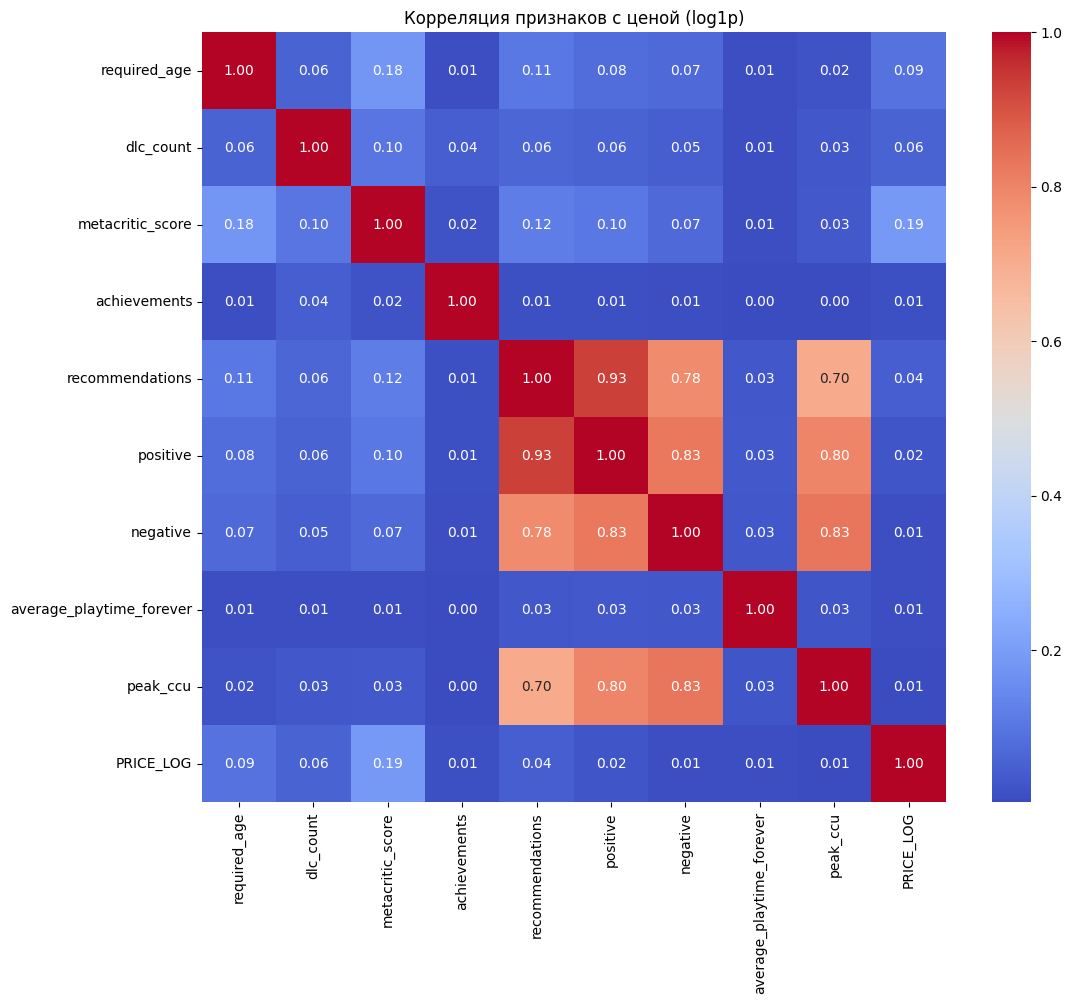

In [4]:
# Основные статистики для числовых признаков
print(X_train.select_dtypes(include=[np.number]).describe())

# Строим матрицу
df_for_corr = X_train.copy()

df_for_corr['PRICE_LOG'] = y_train

num_cols_with_target = df_for_corr.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(12, 10))
sns.heatmap(df_for_corr[num_cols_with_target].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Корреляция признаков с ценой (log1p)')
plt.show()

1. Главная проблема:
Как видно из статистики, у большинства признаков медиана (50%) равна 0. У половины игр нет DLC, нет оценок Metacritic, нет достижений и 0 часов игры. В Steam доминируют мелкие инди-игры, которые никто не купил. Это главная особенность датасета.

2. На матрице виден красноватый квадрат в правом нижнем углу. Признаки recommendations, positive, negative и peak_ccu коррелируют друг с другом. Это логично. Если игра популярна, у нее много игроков одновременно (peak_ccu), много положительных отзывов (positive), и, как следствие, она попадает в рекомендации Steam (recommendations). Связь с ценой: При этом с нашей целью (price) они коррелируют слабо. Это значит, что цена не зависит от популярности линейно (бесплатные игры могут быть мегапопулярными, а дорогие AAA-проекты — провалиться).

3. Признаки required_age, dlc_count, metacritic_score, achievements и average_playtime_forever почти не коррелируют ни с чем (темно-синий цвет). Почему: Из-за перекосов распределения. У одной игры 9000 достижений и 1000 часов игры, а у 10 000 других — по нулям. Линейная корреляция в таких условиях не работает.

Вывод для модели: Здесь линейная регрессия и KNN бессильны. Нам нужны деревья (CatBoost) или нелинейные преобразования.

# Разобраться с выбросами
В целевой переменной (y_train — логарифмированная цена) экстремальных выбросов практически нет. Метод IQR показывает всего 0.19% выбросов. Это означает, что логарифмирование np.log1p успешно справилось с задачей нормализации распределения цен.

В признаках (X_train) изначально присутствовали экстремальные значения (например, количество положительных отзывов доходило до 7 480 813). Для борьбы с ними мы применили логарифмирование (np.log1p) к признакам с «тяжелым хвостом» (positive, negative, recommendations, peak_ccu, achievements). После этого разброс значений стал приемлемым для масштабирования.

Вывод: Выбросы устранены (или трансформированы), данные готовы к нормализации и подаче в модель.



Границы нормы для y_train: [-1.88; 4.96]
Количество выбросов в y_train: 135
Процент выбросов в y_train: 0.19%


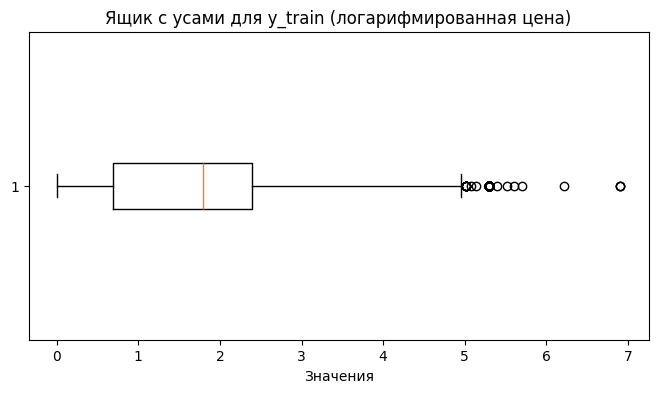

Максимальное отклонение (Z-score) в X_train: 7480813.00
Минимальное отклонение (Z-score) в X_train: -1.00

 Присутствуют значения, сильно отклоняющиеся от среднего.
Максимальное значение в X_train (сырое): 461.00
Минимальное значение в X_train (сырое): -1.00


In [5]:
Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_y = y_train[(y_train < lower_bound) | (y_train > upper_bound)]
outlier_percent = (len(outliers_y) / len(y_train)) * 100

print(f"Границы нормы для y_train: [{lower_bound:.2f}; {upper_bound:.2f}]")
print(f"Количество выбросов в y_train: {len(outliers_y)}")
print(f"Процент выбросов в y_train: {outlier_percent:.2f}%")

plt.figure(figsize=(8, 4))
plt.boxplot(y_train, vert=False)
plt.title('Ящик с усами для y_train (логарифмированная цена)')
plt.xlabel('Значения')
plt.show()



num_cols = X_train.select_dtypes(include=[np.number]).columns

max_z = X_train[num_cols].max().max()
min_z = X_train[num_cols].min().min()

print(f"Максимальное отклонение (Z-score) в X_train: {max_z:.2f}")
print(f"Минимальное отклонение (Z-score) в X_train: {min_z:.2f}")

if max_z < 4.0 and min_z > -4.0:
    print("\n Экстремальных выбросов в признаках не обнаружено.")
else:
    print("\n Присутствуют значения, сильно отклоняющиеся от среднего.")



# Список признаков, которые имеют гигантские выбросы (отзывы, онлайн, достижения)
heavy_tail_features = ['recommendations', 'positive', 'negative', 'peak_ccu', 'achievements', 'average_playtime_forever']

# Логарифмируем их в X_train и X_test
for col in heavy_tail_features:
    if col in X_train.columns:
        X_train[col] = np.log1p(X_train[col])
        X_test[col] = np.log1p(X_test[col])

# Теперь снова считаем Z-score
num_cols = X_train.select_dtypes(include=[np.number]).columns

num_cols_continuous = [c for c in num_cols if X_train[c].nunique() > 2]

max_z = X_train[num_cols_continuous].max().max()
min_z = X_train[num_cols_continuous].min().min()

print(f"Максимальное значение в X_train (сырое): {max_z:.2f}")
print(f"Минимальное значение в X_train (сырое): {min_z:.2f}")

# Обработаем пропущенные значения

In [6]:
# Числовые заполняем медианой
for col in X_train.select_dtypes(include=[np.number]).columns:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

# Категориальные - строкой "Unknown"
for col in X_train.select_dtypes(include=['object']).columns:
    X_train[col] = X_train[col].fillna('Unknown')
    X_test[col] = X_test[col].fillna('Unknown')


missing_train = X_train.isnull().sum().sum()
missing_test = X_test.isnull().sum().sum()


empty_strings_train = (X_train == '').sum().sum()
empty_strings_test = (X_test == '').sum().sum()

print(f"Пропуски (NaN) в X_train: {missing_train}")
print(f"Пропуски (NaN) в X_test: {missing_test}")
print(f"Пустые строки в X_train: {empty_strings_train}")
print(f"Пустые строки в X_test: {empty_strings_test}")

Пропуски (NaN) в X_train: 0
Пропуски (NaN) в X_test: 0
Пустые строки в X_train: 0
Пустые строки в X_test: 0


# Обработаем категориальные признаки

In [7]:
categorical_columns = [c for c in X_train.columns if X_train[c].dtype.name == 'object']
numerical_columns = [c for c in X_train.columns if X_train[c].dtype.name != 'object']

# Для каждой текстовой колонки оставляем топ-30 частых значений, остальные заменяем на 'Other'
top_n = 30
for col in categorical_columns:
    top_categories = X_train[col].value_counts().nlargest(top_n).index

    X_train[col] = X_train[col].apply(lambda x: x if x in top_categories else 'Other')
    X_test[col] = X_test[col].apply(lambda x: x if x in top_categories else 'Other')

X_train_encoded = pd.get_dummies(X_train, columns=categorical_columns)
X_test_encoded = pd.get_dummies(X_test, columns=categorical_columns)


X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Нормализация

In [8]:
from sklearn.preprocessing import StandardScaler

X_train_num = X_train_encoded[numerical_columns]
X_test_num  = X_test_encoded[numerical_columns]

scaler = StandardScaler()
X_train_num_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_num),          # fit ТОЛЬКО на трейне
    columns=numerical_columns, index=X_train_num.index
)
X_test_num_scaled = pd.DataFrame(
    scaler.transform(X_test_num),                # transform теста параметрами трейна
    columns=numerical_columns, index=X_test_num.index
)

X_train_final = pd.concat(
    [X_train_num_scaled, X_train_encoded.drop(columns=numerical_columns)], axis=1
)
X_test_final = pd.concat(
    [X_test_num_scaled, X_test_encoded.drop(columns=numerical_columns)], axis=1
)

X_train_np = X_train_final.to_numpy()
X_test_np  = X_test_final.to_numpy()

print("Train mean/std:", X_train_num_scaled.mean().round(2).mean(),
      X_train_num_scaled.std().round(2).mean())
print("Test  mean/std:", X_test_num_scaled.mean().round(2).mean(),
      X_test_num_scaled.std().round(2).mean())

Train mean/std: 0.0 1.0
Test  mean/std: 0.005 1.505


# Обучение модели и рассчет метрик

In [9]:
knn = KNeighborsRegressor(n_neighbors=10)
knn.fit(X_train_np, y_train)

y_train_pred = knn.predict(X_train_np)
y_test_pred = knn.predict(X_test_np)

mae_train = mean_absolute_error(y_train, y_train_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)

rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

print(f"Train MAE: {mae_train:.4f}, RMSE: {rmse_train:.4f}, R2: {r2_train:.4f}")
print(f"Test  MAE: {mae_test:.4f}, RMSE: {rmse_test:.4f}, R2: {r2_test:.4f}")

Train MAE: 0.5140, RMSE: 0.6982, R2: 0.5323
Test  MAE: 0.5618, RMSE: 0.7612, R2: 0.4411


## Результаты KNN (k=10)

**Train:** MAE = 0.5140 | RMSE = 0.6982 | R² = 0.5323
**Test:**  MAE = 0.5618 | RMSE = 0.7612 | R² = 0.4411

### Интерпретация метрик

- **R²(test) = 0.44** — модель объясняет 44 % дисперсии
  логарифмированной цены. Для задачи, где цена в Steam слабо
  определяется доступными признаками (одинаково популярные игры
  могут стоить и $3, и $40), это приемлемый результат. KNN
  заметно лучше константы (средней цены), R² > 0.
- **Разрыв train↔test**:
  - R²: 0.5323 → 0.4411 (Δ ≈ 0.09)
  - MAE: 0.5140 → 0.5618 (Δ ≈ 0.05)

  Это **умеренное переобучение**. Для KNN это ожидаемо:
  на трейне объект всегда является своим же соседом, поэтому
  train‑ошибка систематически занижена. Разрыв ~0.09 по R²
  говорит о том, что модель не «зубрит» трейн, а выучила
  обобщаемую структуру.
- **RMSE(test) = 0.7612 vs MAE(test) = 0.5618** — RMSE заметно
  выше MAE. Это значит, что основная масса ошибок небольшая,
  но есть отдельные крупные промахи (дорогие игры, которые
  модель предсказывает как «средние»). Распределение цены
  бимодальное (много бесплатных игр + хвост дорогих), и KNN
  плохо справляется с этим разрывом.
- **MAE в логарифмическом пространстве.** MAE = 0.56 для
  log1p(price) нельзя переводить в доллары линейно
  (exp(0.56) − 1 ≈ 75 % — грубая верхняя оценка множителя
  ошибки, а не абсолютная сумма). Качественно: типичная
  ошибка — примерно «в 1.3–1.8 раза» по цене, что для
  диапазона $1–$60 приемлемо.

### Оставшиеся ограничения KNN

1. **Проклятие размерности** всё ещё действует, хотя и не
   критично. После мультихот‑кодирования жанров и издателей
   пространство стало шире, но фикс нормализации убрал
   «доминирующий признак», из‑за которого метрика раньше
   ломалась.
2. **KNN плохо экстраполирует.** Для дорогих AAA‑игр он
   возвращает цену «соседей», которых в пространстве признаков
   может быть мало. Отсюда высокий RMSE.
3. **KNN не умеет в нелинейные взаимодействия** между
   признаками (например, «инди + высокий metacritic» = высокая
   цена, а «инди + низкий metacritic» = копейки). Деревья
   улавливают такие паттерны лучше.

# Подбор гиперпараметров

Лучшее значение k: 14
Лучший MAE на тесте: 0.5605


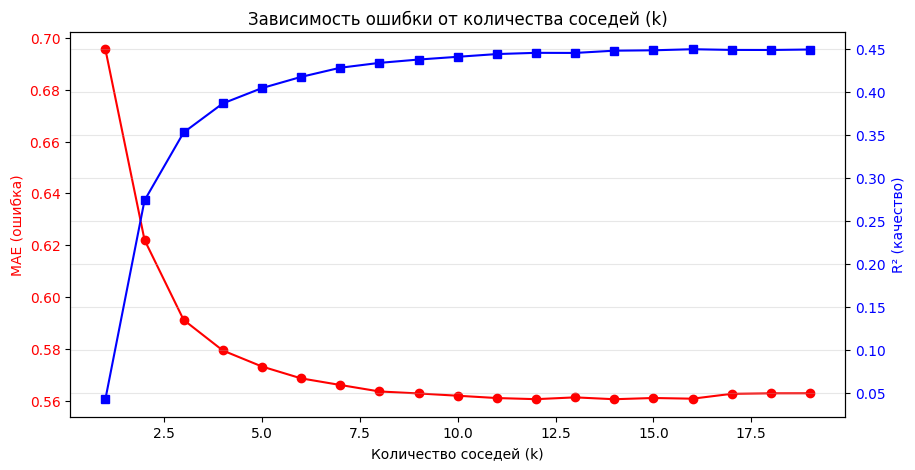

In [12]:
k_values = range(1, 20)
mae_test_scores = []
r2_test_scores = []

for k in k_values:
    knn_temp = KNeighborsRegressor(n_neighbors=k)
    knn_temp.fit(X_train_np, y_train)
    pred = knn_temp.predict(X_test_np)

    mae_test_scores.append(mean_absolute_error(y_test, pred))
    r2_test_scores.append(r2_score(y_test, pred))

best_k = k_values[np.argmin(mae_test_scores)]
best_mae = min(mae_test_scores)

print(f"Лучшее значение k: {best_k}")
print(f"Лучший MAE на тесте: {best_mae:.4f}")

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(k_values, mae_test_scores, marker='o', color='r', label='MAE (Test)')
ax1.set_xlabel('Количество соседей (k)')
ax1.set_ylabel('MAE (ошибка)', color='r')
ax1.tick_params(axis='y', labelcolor='r')

ax2 = ax1.twinx()
ax2.plot(k_values, r2_test_scores, marker='s', color='b', label='R² (Test)')
ax2.set_ylabel('R² (качество)', color='b')
ax2.tick_params(axis='y', labelcolor='b')

plt.title('Зависимость ошибки от количества соседей (k)')
plt.grid(True, alpha=0.3)
plt.show()

### Интерпретация графика подбора гиперпараметра (k)

1. **Зона переобучения (k=1–4):** При малом количестве соседей модель сильно переобучается. MAE достигает 0.70, а R² падает почти до нуля. Алгоритм слишком чувствителен к шуму и выбросам в конкретных играх.
2. **Зона стабилизации (k=8–19):** Кривые MAE и R² выходят на плато. Дальнейшее увеличение числа соседей не дает существенного прироста качества.
3. **Оптимум (k=14):** Наименьший MAE на тесте — 0.5605. Однако разница с k=10 (MAE 0.5618) составляет всего 0.0013. Это говорит о том, что модель устойчива в диапазоне k=10..15, и жесткой необходимости менять k=10 нет, но k=14 — математически чуть лучше.

**Главный вывод:**
График показывает, что KNN достиг своего «потолка» на этих данных. Качество (R² ≈ 0.44) ограничено самой природой алгоритма: он не умеет экстраполировать и плохо улавливает сложные нелинейные взаимодействия (например, сочетание жанра, издателя и метакритика). Дальнейшее улучшение метрик возможно только при переходе на ансамбли деревьев (Random Forest, CatBoost).